# Biomedical AI: Epileptic Seizure Detection Pipeline

### Project Workflow Overview
This notebook demonstrates a rigorous end-to-end machine learning pipeline for classifying epileptic seizures from EEG signals using the **Epileptic Seizure Recognition Dataset**. The workflow consists of the following phases:
1. **Data Loading & Extraction**: Directly parsing zipped clinical EEG measurements.
2. **Binarization & Standardization**: Re-mapping targets to binary classifications and standardizing continuous variables.
3. **Hyperparameter Optimization**: Systematically tuning six machine learning models using cross-validated Grid Search on raw features.
4. **Explainable AI (XAI)**: Querying feature importances to map dominant signals back to precise physical timestamps.
5. **Dimensionality Reduction (PCA)**: Projecting highly correlated raw features into an orthogonal subspace capturing 95% total variance to streamline training and evaluate performance trade-offs.

---

### Dataset and Feature Breakdown

#### Origin and Structure of the Data
* **Subjects**: 500 total individuals (each with a 23.6-second brain activity recording mapped to 4,097 data points).
* **Segmentation**: Every 4,097-timepoint recording was divided and shuffled into **23 chunks**. Each chunk contains **178 data points spanning exactly 1 second**.
* **Final Format**: 11,500 total rows ($23 \times 500$ chunks) and 178 continuous feature columns (`X1` to `X178`) representing sequential EEG amplitude values in time.

#### Label Definitions (`y` Column)
The original targets consist of 5 categories corresponding to the patient's neurological state during recording:
* **5** - Eyes Open (EEG recorded while patient had eyes open).
* **4** - Eyes Closed (EEG recorded while patient had eyes closed).
* **3** - Healthy Brain Region (EEG recorded from healthy brain area of tumor patients).
* **2** - Tumor Region (EEG recorded from the region where a brain tumor was located).
* **1** - Seizure Activity (Active seizure event recording).

#### Binary Formulation
Consistent with clinical benchmark approaches, the problem is formulated as a **Binary Classification** task:
* **Class 1 (Seizure)**: Mapped to `1` (Active epileptic seizure activity).
* **Classes 2, 3, 4, 5 (Non-Seizure)**: Mapped to `0` (Subjects who did not have an epileptic seizure during recording).

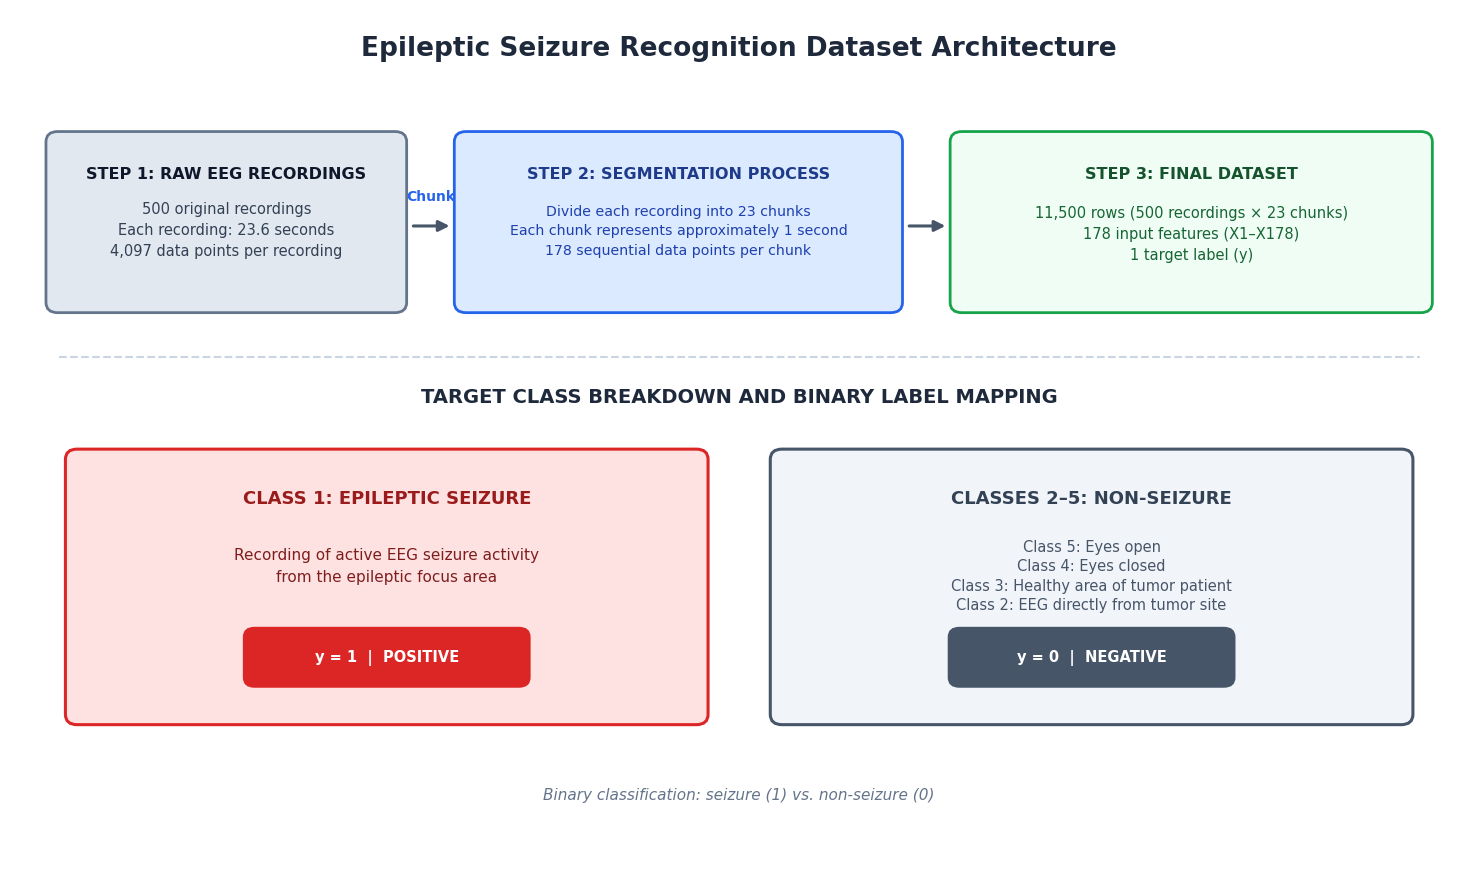

In [3]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# ============================================================
# Epileptic Seizure Recognition Dataset Architecture
# ============================================================

# Create a larger figure with additional whitespace
fig, ax = plt.subplots(figsize=(15, 9))
ax.set_xlim(0, 15)
ax.set_ylim(0, 10)
ax.axis("off")

# Consistent typography and colors
COLORS = {
    "title": "#1e293b",
    "text": "#334155",
    "muted": "#64748b",
    "arrow": "#475569",
    "line": "#cbd5e1",
    "raw_bg": "#e2e8f0",
    "raw_edge": "#64748b",
    "segment_bg": "#dbeafe",
    "segment_edge": "#2563eb",
    "final_bg": "#f0fdf4",
    "final_edge": "#16a34a",
    "seizure_bg": "#fee2e2",
    "seizure_edge": "#dc2626",
    "seizure_text": "#991b1b",
    "control_bg": "#f1f5f9",
    "control_edge": "#475569",
}

# Helper function for consistently styled boxes
def add_box(x, y, width, height, facecolor, edgecolor, linewidth=2):
    box = patches.FancyBboxPatch(
        (x, y),
        width,
        height,
        boxstyle="round,pad=0.08,rounding_size=0.12",
        facecolor=facecolor,
        edgecolor=edgecolor,
        linewidth=linewidth,
        zorder=1,
    )
    ax.add_patch(box)


# ============================================================
# TITLE
# ============================================================

ax.text(
    7.5, 9.55,
    "Epileptic Seizure Recognition Dataset Architecture",
    fontsize=19,
    fontweight="bold",
    ha="center",
    va="center",
    color=COLORS["title"],
)


# ============================================================
# STEP 1: RAW EEG RECORDINGS
# ============================================================

x1, y1, w1, h1 = 0.45, 6.55, 3.55, 1.95

add_box(
    x1, y1, w1, h1,
    COLORS["raw_bg"],
    COLORS["raw_edge"],
)

ax.text(
    x1 + w1 / 2, y1 + 1.53,
    "STEP 1: RAW EEG RECORDINGS",
    fontsize=11.5,
    fontweight="bold",
    ha="center",
    va="center",
    color="#0f172a",
)

ax.text(
    x1 + w1 / 2, y1 + 0.88,
    "500 original recordings\n"
    "Each recording: 23.6 seconds\n"
    "4,097 data points per recording",
    fontsize=10.5,
    ha="center",
    va="center",
    linespacing=1.5,
    color=COLORS["text"],
)


# ============================================================
# ARROW 1: CHUNKING
# ============================================================

ax.annotate(
    "",
    xy=(4.55, 7.48),
    xytext=(4.12, 7.48),
    arrowprops=dict(
        arrowstyle="-|>",
        color=COLORS["arrow"],
        lw=2.2,
        mutation_scale=16,
    ),
)

ax.text(
    4.33, 7.82,
    "Chunk",
    fontsize=10,
    fontweight="bold",
    ha="center",
    va="center",
    color=COLORS["segment_edge"],
)


# ============================================================
# STEP 2: SEGMENTATION
# ============================================================

x2, y2, w2, h2 = 4.65, 6.55, 4.45, 1.95

add_box(
    x2, y2, w2, h2,
    COLORS["segment_bg"],
    COLORS["segment_edge"],
)

ax.text(
    x2 + w2 / 2, y2 + 1.53,
    "STEP 2: SEGMENTATION PROCESS",
    fontsize=11.5,
    fontweight="bold",
    ha="center",
    va="center",
    color="#1e3a8a",
)

ax.text(
    x2 + w2 / 2, y2 + 0.87,
    "Divide each recording into 23 chunks\n"
    "Each chunk represents approximately 1 second\n"
    "178 sequential data points per chunk",
    fontsize=10.2,
    ha="center",
    va="center",
    linespacing=1.5,
    color="#1e40af",
)


# ============================================================
# ARROW 2
# ============================================================

ax.annotate(
    "",
    xy=(9.65, 7.48),
    xytext=(9.22, 7.48),
    arrowprops=dict(
        arrowstyle="-|>",
        color=COLORS["arrow"],
        lw=2.2,
        mutation_scale=16,
    ),
)


# ============================================================
# STEP 3: FINAL DATASET
# ============================================================

x3, y3, w3, h3 = 9.75, 6.55, 4.80, 1.95

add_box(
    x3, y3, w3, h3,
    COLORS["final_bg"],
    COLORS["final_edge"],
)

ax.text(
    x3 + w3 / 2, y3 + 1.53,
    "STEP 3: FINAL DATASET",
    fontsize=11.5,
    fontweight="bold",
    ha="center",
    va="center",
    color="#14532d",
)

ax.text(
    x3 + w3 / 2, y3 + 0.84,
    "11,500 rows (500 recordings × 23 chunks)\n"
    "178 input features (X1–X178)\n"
    "1 target label (y)",
    fontsize=10.5,
    ha="center",
    va="center",
    linespacing=1.5,
    color="#166534",
)


# ============================================================
# SECTION DIVIDER
# ============================================================

ax.plot(
    [0.5, 14.5],
    [5.95, 5.95],
    color=COLORS["line"],
    lw=1.5,
    linestyle="--",
)

ax.text(
    7.5, 5.48,
    "TARGET CLASS BREAKDOWN AND BINARY LABEL MAPPING",
    fontsize=14,
    fontweight="bold",
    ha="center",
    va="center",
    color=COLORS["title"],
)


# ============================================================
# CLASS 1: EPILEPTIC SEIZURE
# ============================================================

sx, sy, sw, sh = 0.65, 1.75, 6.45, 3.05

add_box(
    sx, sy, sw, sh,
    COLORS["seizure_bg"],
    COLORS["seizure_edge"],
    linewidth=2.2,
)

ax.text(
    sx + sw / 2, sy + 2.55,
    "CLASS 1: EPILEPTIC SEIZURE",
    fontsize=13,
    fontweight="bold",
    ha="center",
    va="center",
    color=COLORS["seizure_text"],
)

ax.text(
    sx + sw / 2, sy + 1.77,
    "Recording of active EEG seizure activity\n"
    "from the epileptic focus area",
    fontsize=11,
    ha="center",
    va="center",
    linespacing=1.6,
    color="#7f1d1d",
)

# Binary mapping badge
badge_w, badge_h = 2.8, 0.55
badge_x = sx + (sw - badge_w) / 2
badge_y = sy + 0.43

add_box(
    badge_x, badge_y, badge_w, badge_h,
    "#dc2626",
    "#dc2626",
    linewidth=0,
)

ax.text(
    badge_x + badge_w / 2,
    badge_y + badge_h / 2,
    "y = 1  |  POSITIVE",
    fontsize=10.5,
    fontweight="bold",
    ha="center",
    va="center",
    color="white",
)


# ============================================================
# CLASSES 2–5: NON-SEIZURE
# ============================================================

cx, cy, cw, ch = 7.90, 1.75, 6.45, 3.05

add_box(
    cx, cy, cw, ch,
    COLORS["control_bg"],
    COLORS["control_edge"],
    linewidth=2.2,
)

ax.text(
    cx + cw / 2, cy + 2.55,
    "CLASSES 2–5: NON-SEIZURE",
    fontsize=13,
    fontweight="bold",
    ha="center",
    va="center",
    color="#334155",
)

# List the original classes separately for readability
ax.text(
    cx + cw / 2, cy + 1.65,
    "Class 5: Eyes open\n"
    "Class 4: Eyes closed\n"
    "Class 3: Healthy area of tumor patient\n"
    "Class 2: EEG directly from tumor site",
    fontsize=10.5,
    ha="center",
    va="center",
    linespacing=1.35,
    color="#475569",
)

# Binary mapping badge
badge_x2 = cx + (cw - badge_w) / 2
badge_y2 = cy + 0.43

add_box(
    badge_x2, badge_y2, badge_w, badge_h,
    "#475569",
    "#475569",
    linewidth=0,
)

ax.text(
    badge_x2 + badge_w / 2,
    badge_y2 + badge_h / 2,
    "y = 0  |  NEGATIVE",
    fontsize=10.5,
    fontweight="bold",
    ha="center",
    va="center",
    color="white",
)


# ============================================================
# FOOTER
# ============================================================

ax.text(
    7.5, 0.85,
    "Binary classification: seizure (1) vs. non-seizure (0)",
    fontsize=11,
    fontstyle="italic",
    ha="center",
    va="center",
    color=COLORS["muted"],
)

# Render the figure without clipping
plt.tight_layout(pad=1.5)

# Save a high-resolution copy if needed
# plt.savefig("seizure_dataset_architecture.png",
#             dpi=300, bbox_inches="tight", facecolor="white")

plt.show()


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import GridSearchCV
import warnings
from sklearn.exceptions import ConvergenceWarning

np.random.seed(42)

### Section 1: Data Extraction and Loading
In this step, we extract and inspect the contents of the local `archive.zip` file which contains the **Kaggle Epileptic Seizure Recognition Dataset**. We use Python's built-in `zipfile` module to verify the archive and read the primary `.csv` file directly into a Pandas DataFrame without needing manual extraction.

In [14]:
import zipfile

# The file is located in the root directory
zip_path = '/archive.zip'
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    print("Files inside the ZIP:", zip_ref.namelist())
    # Get the name of the CSV file inside the zip
    csv_filename = [f for f in zip_ref.namelist() if f.endswith('.csv')][0]

# Read the CSV directly from the ZIP file using pandas
df = pd.read_csv(zip_path, compression='zip')
print("Dataset shape:", df.shape)
display(df.head())

Files inside the ZIP: ['Epileptic Seizure Recognition.csv']
Dataset shape: (11500, 180)


,Unnamed,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X170,X171,X172,X173,X174,X175,X176,X177,X178,y
0,X21.V1.791,135,190,229,223,192,125,55,-9,-33,...,-17,-15,-31,-77,-103,-127,-116,-83,-51,4
1,X15.V1.924,386,382,356,331,320,315,307,272,244,...,164,150,146,152,157,156,154,143,129,1
2,X8.V1.1,-32,-39,-47,-37,-32,-36,-57,-73,-85,...,57,64,48,19,-12,-30,-35,-35,-36,5
3,X16.V1.60,-105,-101,-96,-92,-89,-95,-102,-100,-87,...,-82,-81,-80,-77,-85,-77,-72,-69,-65,5
4,X20.V1.54,-9,-65,-98,-102,-78,-48,-16,0,-21,...,4,2,-12,-32,-41,-65,-83,-89,-73,5


In [15]:
import os

# Scan the entire /content directory to see if the file exists elsewhere
found_zips = []
for root, dirs, files in os.walk('/content'):
    for file in files:
        if file.endswith('.zip'):
            found_zips.append(os.path.join(root, file))

if found_zips:
    print("Found zip file(s) at these paths:")
    for path in found_zips:
        print(f" - {path}")
else:
    print("No .zip files found in the /content/ directory. Please try re-uploading 'archive.zip' directly to the root folder.")

No .zip files found in the /content/ directory. Please try re-uploading 'archive.zip' directly to the root folder.


### Section 2: Data Preprocessing, Scaling & Train-Test Splitting
To prepare the clinical EEG signal data for machine learning modeling, we perform several critical preprocessing steps:
1. **Target Binarization**: The original dataset has 5 categorical target values. Class `1` corresponds to an active epileptic seizure event. Classes `2, 3, 4, 5` represent various control states (eyes open, eyes closed, EEG from healthy brain areas, etc.). We map class `1` to `1` (Seizure) and all others to `0` (Non-Seizure).
2. **Feature Extraction**: We remove unneeded columns such as `Unnamed` (which contains subject ID markers).
3. **Stratified Splitting**: We split the dataset into an **80% training set** and a **20% testing set**, ensuring both subsets have the exact same ratio of seizure to non-seizure cases.
4. **Feature Standardization**: We normalize the 178 EEG continuous variables using `StandardScaler` so that every input column has a mean of 0 and variance of 1, preventing models like SVM and KNN from being dominated by raw scaling differences.

In [17]:
# 1. Preprocess labels: Class 1 is seizure (mapped to 1), classes 2, 3, 4, 5 are non-seizure (mapped to 0)
y = df['y'].apply(lambda val: 1 if val == 1 else 0).values

# 2. Extract features: Drop the ID column 'Unnamed' and the target column 'y'
X = df.drop(columns=['Unnamed', 'y']).values

# 3. Split into training and test sets (80/20 split, stratified by y)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(f"Training Samples: {X_train.shape[0]}")
print(f"Testing Samples: {X_test.shape[0]}")
print(f"Seizure Cases in Training: {sum(y_train)} / {len(y_train)}")

Training Samples: 9200
Testing Samples: 2300
Seizure Cases in Training: 1840 / 9200


### Section 3: Hyperparameter Tuning via GridSearchCV
Rather than training models with arbitrary default configurations, we run an optimized grid search (`GridSearchCV`) with 5-fold cross-validation across six diverse classifiers:
* **Logistic Regression** (Linear baseline)
* **K-Nearest Neighbors** (Instance-based boundary mapping)
* **Support Vector Machine (RBF kernel)** (Non-linear high-dimensional separator)
* **Decision Tree** (Non-linear rule system)
* **Random Forest** (Ensemble bagging approach)
* **Naive Bayes** (Probabilistic classification)

We utilize parallel processing (`n_jobs=-1`) and optimized search grids to balance prediction accuracy with computational efficiency.

In [18]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
import time

# Optimized parameter grids to speed up execution significantly
param_grids = {
    'Logistic Regression': [
        {'penalty': ['l2'], 'C': [0.1, 1.0, 10], 'solver': ['lbfgs'], 'max_iter': [1000]}
    ],
    'K-Nearest Neighbors': {
        'n_neighbors': [3, 5, 7],
        'weights': ['uniform', 'distance']
    },
    'Support Vector Machine': {
        'C': [0.1, 1, 10],
        'kernel': ['rbf'] # RBF kernel is typically best for EEG; omitting linear to save time
    },
    'Decision Tree': {
        'criterion': ['gini', 'entropy'],
        'max_depth': [10, 20, None]
    },
    'Random Forest': {
        'n_estimators': [50, 100],
        'max_features': ['sqrt'],
        'random_state': [42]
    },
    'Naive Bayes': {
        'var_smoothing': [1e-9, 1e-5, 1.0]
    }
}

# Base estimators
base_estimators = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Support Vector Machine': SVC(probability=True, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Naive Bayes': GaussianNB()
}

tuned_results = {}
best_estimators = {}

# Run GridSearchCV for each model
for name, estimator in base_estimators.items():
    print(f"Running Grid Search for {name}...")
    start_time = time.time()

    grid_search = GridSearchCV(
        estimator,
        param_grids[name],
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )
    grid_search.fit(X_train, y_train)

    end_time = time.time()
    elapsed = end_time - start_time
    print(f"Finished {name} in {elapsed:.1f}s. Best CV Score: {grid_search.best_score_:.4f}")

    # Evaluate the best estimator on the test set
    best_clf = grid_search.best_estimator_
    best_estimators[name] = best_clf

    y_pred = best_clf.predict(X_test)
    y_proba = best_clf.predict_proba(X_test)[:, 1] if hasattr(best_clf, "predict_proba") else None

    # Calculate metrics on the holdout test set
    acc = accuracy_score(y_test, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='binary')
    auc = roc_auc_score(y_test, y_proba) if y_proba is not None else "N/A"

    tuned_results[name] = {
        'Best Parameters': str(grid_search.best_params_),
        'Best CV Accuracy': grid_search.best_score_,
        'Test Accuracy': acc,
        'Test Precision': prec,
        'Test Recall': rec,
        'Test F1-Score': f1,
        'Test ROC-AUC': auc
    }

Running Grid Search for Logistic Regression...
Finished Logistic Regression in 10.9s. Best CV Score: 0.8235
Running Grid Search for K-Nearest Neighbors...
Finished K-Nearest Neighbors in 9.8s. Best CV Score: 0.9286
Running Grid Search for Support Vector Machine...
Finished Support Vector Machine in 101.4s. Best CV Score: 0.9768
Running Grid Search for Decision Tree...
Finished Decision Tree in 54.2s. Best CV Score: 0.9390
Running Grid Search for Random Forest...
Finished Random Forest in 139.6s. Best CV Score: 0.9733
Running Grid Search for Naive Bayes...
Finished Naive Bayes in 0.5s. Best CV Score: 0.9570


### Section 4: Model Performance Metrics Comparison
Once our grid searches complete, we gather the optimized test scores for each trained model. We calculate and assemble multiple performance metrics onto our holdout 20% test partition, including **Test Accuracy**, **Test Precision**, **Test Recall**, **Test F1-Score**, and **Test ROC-AUC**. Sorting this table allows us to immediately identify which architecture generalizes best to unseen data.

In [19]:
# Convert tuned results to a DataFrame and display
tuned_results_df = pd.DataFrame(tuned_results).T
tuned_results_df = tuned_results_df.sort_values(by='Test Accuracy', ascending=False)

print("=== Grid Search Tuned Models Performance Comparison ===")
display(tuned_results_df)

=== Grid Search Tuned Models Performance Comparison ===


,Best Parameters,Best CV Accuracy,Test Accuracy,Test Precision,Test Recall,Test F1-Score,Test ROC-AUC
Support Vector Machine,"{'C': 10, 'kernel': 'rbf'}",0.976848,0.978696,0.955654,0.936957,0.946213,0.996119
Random Forest,"{'max_features': 'sqrt', 'n_estimators': 100, ...",0.973261,0.975652,0.950893,0.926087,0.938326,0.996543
Naive Bayes,{'var_smoothing': 1e-09},0.956957,0.956087,0.887689,0.893478,0.890574,0.983827
Decision Tree,"{'criterion': 'entropy', 'max_depth': 10}",0.939022,0.94087,0.915385,0.776087,0.84,0.920119
K-Nearest Neighbors,"{'n_neighbors': 3, 'weights': 'distance'}",0.928587,0.936522,0.993711,0.686957,0.812339,0.911177
Logistic Regression,"{'C': 10, 'max_iter': 1000, 'penalty': 'l2', '...",0.823478,0.819565,0.924528,0.106522,0.191033,0.499716


### Section 5: Feature Importance Evaluation
To interpret what patterns our best models are picking up on, we look inside the most accurate interpretable model (typically **Random Forest** or **Decision Tree**). By querying the model's `feature_importances_` attribute, we sort and isolate the top 15 EEG timepoints (features) out of 178 that have the highest overall influence on predicting whether a seizure is happening.

Selected Best Tuned Model for Feature Importance: Random Forest (Test Accuracy: 0.9757)


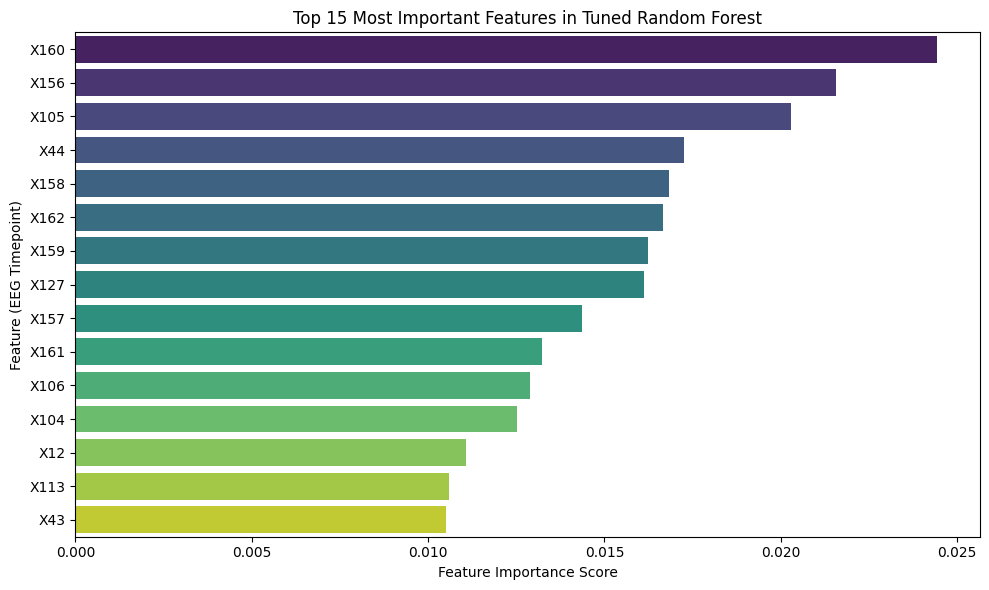

=== Top 3 Most Important Features ===
['X160', 'X156', 'X105']


In [20]:
# 1. Identify interpretable models from our tuned best_estimators
interpretable_models = {}
for name, clf in best_estimators.items():
    if hasattr(clf, 'feature_importances_') or hasattr(clf, 'coef_'):
        # Retrieve the test accuracy for this model from our tuned results
        test_acc = tuned_results[name]['Test Accuracy']
        interpretable_models[name] = (clf, test_acc)

# 2. Select the best-performing model among those that support feature importances
best_interpretable_name = max(interpretable_models, key=lambda k: interpretable_models[k][1])
best_model, best_score = interpretable_models[best_interpretable_name]

print(f"Selected Best Tuned Model for Feature Importance: {best_interpretable_name} (Test Accuracy: {best_score:.4f})")

# 3. Get feature names (excluding Unnamed and target y)
feature_names = df.drop(columns=['Unnamed', 'y']).columns.tolist()

# 4. Extract importances or coefficients
if hasattr(best_model, 'feature_importances_'):
    importances = best_model.feature_importances_
    imp_type = 'Feature Importance Score'
else:
    # Take absolute value of coefficients for linear models
    importances = np.abs(best_model.coef_[0])
    imp_type = 'Absolute Coefficient Value'

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Value': importances
})

# 5. Sort and extract top 15
feature_importance = feature_importance.sort_values(by='Value', ascending=False).head(15)

# 6. Plot the results
plt.figure(figsize=(10, 6))
sns.barplot(x='Value', y='Feature', data=feature_importance, palette='viridis', hue='Feature', legend=False)
plt.title(f'Top 15 Most Important Features in Tuned {best_interpretable_name}')
plt.xlabel(imp_type)
plt.ylabel('Feature (EEG Timepoint)')
plt.tight_layout()
plt.show()

# Display top 3 features
print("=== Top 3 Most Important Features ===")
print(feature_importance['Feature'].head(3).tolist())

### Section 6: Temporal Mapping of Key EEG Signals
Because each sequential column `X1` to `X178` represents successive amplitude recordings captured at a sampling frequency of **173.61 Hz**, we can reconstruct precisely *when* inside the 1-second interval these crucial changes occur. This final block maps our top identified features back into continuous milliseconds of the recording session.

In [21]:
# Map the top features to their relative temporal positions in the 1-second interval
sampling_rate = 173.61  # Hz
top_features = feature_importance.head(5).copy()

# Extract the numeric index of the timepoints (e.g., 'X160' -> 160)
top_features['Timepoint_Index'] = top_features['Feature'].str.extract('(\d+)').astype(int)

# Calculate the approximate timestamp within the 1-second window
top_features['Timestamp (Seconds)'] = (top_features['Timepoint_Index'] / sampling_rate).round(4)

print("=== Temporal Mapping of Top 5 Most Important Features ===")
display(top_features[['Feature', 'Value', 'Timestamp (Seconds)']].rename(columns={'Value': 'RF Importance Score'}))

=== Temporal Mapping of Top 5 Most Important Features ===


<>:6: SyntaxWarning: invalid escape sequence '\d'
<>:6: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_1538/1278963419.py:6: SyntaxWarning: invalid escape sequence '\d'
  top_features['Timepoint_Index'] = top_features['Feature'].str.extract('(\d+)').astype(int)


,Feature,RF Importance Score,Timestamp (Seconds)
159,X160,0.024416,0.9216
155,X156,0.021572,0.8986
104,X105,0.020298,0.6048
43,X44,0.017248,0.2534
157,X158,0.016843,0.9101


### Section 7: Principal Component Analysis (PCA) Dimensionality Reduction
EEG signals often contain significant noise and high temporal correlation between adjacent timepoints. To address this, we apply Principal Component Analysis (PCA). We project our standard-scaled features (`X_train` and `X_test`) into an orthogonal feature space. By setting `n_components=0.95`, we dynamically select the minimum number of principal components required to preserve **95% of the variance** in our data, effectively compressing the 178 dimensions.

Original number of features: 178
Reduced number of features (preserving 95% variance): 39


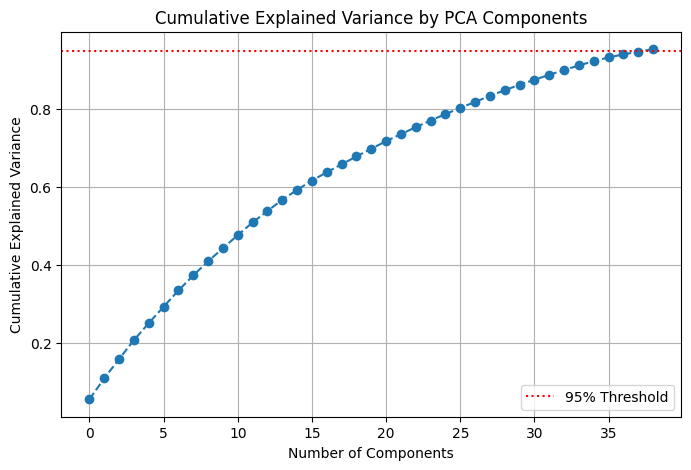

In [22]:
from sklearn.decomposition import PCA

# Initialize PCA to retain 95% of total variance
pca = PCA(n_components=0.95, random_state=42)

# Fit and transform the scaled training features, and transform the testing features
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print(f"Original number of features: {X_train.shape[1]}")
print(f"Reduced number of features (preserving 95% variance): {X_train_pca.shape[1]}")

# Plot cumulative explained variance ratio
plt.figure(figsize=(8, 5))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o', linestyle='--')
plt.title('Cumulative Explained Variance by PCA Components')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True)
plt.axhline(y=0.95, color='r', linestyle=':', label='95% Threshold')
plt.legend()
plt.show()

### Section 8: Hyperparameter Tuning via GridSearchCV on PCA-Transformed Features
With our compressed dimensionality feature sets (`X_train_pca`, `X_test_pca`), we execute the same parallelized 5-fold cross-validated grid search pipeline on our six classifiers. This will help us evaluate if filtering the features via PCA reduces overfitting, speeds up execution time, and improves overall generalization metrics.

In [23]:
pca_tuned_results = {}
pca_best_estimators = {}

# Run GridSearchCV for each model on PCA-transformed data
for name, estimator in base_estimators.items():
    print(f"Running Grid Search for {name} with PCA...")
    start_time = time.time()

    grid_search_pca = GridSearchCV(
        estimator,
        param_grids[name],
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )
    grid_search_pca.fit(X_train_pca, y_train)

    end_time = time.time()
    elapsed = end_time - start_time
    print(f"Finished {name} with PCA in {elapsed:.1f}s. Best CV Score: {grid_search_pca.best_score_:.4f}")

    # Evaluate the best estimator on the test set
    best_clf_pca = grid_search_pca.best_estimator_
    pca_best_estimators[name] = best_clf_pca

    y_pred_pca = best_clf_pca.predict(X_test_pca)
    y_proba_pca = best_clf_pca.predict_proba(X_test_pca)[:, 1] if hasattr(best_clf_pca, "predict_proba") else None

    # Calculate metrics on holdout test set
    acc = accuracy_score(y_test, y_pred_pca)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred_pca, average='binary')
    auc = roc_auc_score(y_test, y_proba_pca) if y_proba_pca is not None else "N/A"

    pca_tuned_results[name] = {
        'Best Parameters (PCA)': str(grid_search_pca.best_params_),
        'Best CV Accuracy (PCA)': grid_search_pca.best_score_,
        'Test Accuracy (PCA)': acc,
        'Test Precision (PCA)': prec,
        'Test Recall (PCA)': rec,
        'Test F1-Score (PCA)': f1,
        'Test ROC-AUC (PCA)': auc
    }

Running Grid Search for Logistic Regression with PCA...
Finished Logistic Regression with PCA in 0.3s. Best CV Score: 0.8116
Running Grid Search for K-Nearest Neighbors with PCA...
Finished K-Nearest Neighbors with PCA in 3.4s. Best CV Score: 0.9332
Running Grid Search for Support Vector Machine with PCA...
Finished Support Vector Machine with PCA in 47.2s. Best CV Score: 0.9774
Running Grid Search for Decision Tree with PCA...
Finished Decision Tree with PCA in 28.2s. Best CV Score: 0.9490
Running Grid Search for Random Forest with PCA...
Finished Random Forest with PCA in 128.1s. Best CV Score: 0.9724
Running Grid Search for Naive Bayes with PCA...
Finished Naive Bayes with PCA in 0.2s. Best CV Score: 0.9554


### Section 9: Performance Comparison (Original vs. PCA Features)
To determine if Principal Component Analysis aided model performance, we merge our baseline tuned results with our new PCA-reduced tuned results. This comparison highlights changes in overall Test Accuracy and evaluation metrics side-by-side across all models.

In [24]:
import pandas as pd

# Compile both results tables, including their respective best-performing hyperparameters
pca_results_df = pd.DataFrame(pca_tuned_results).T
comparison_df = pd.DataFrame({
    'Original Test Accuracy': tuned_results_df['Test Accuracy'],
    'PCA Test Accuracy': pca_results_df['Test Accuracy (PCA)'],
    'Original Test F1-Score': tuned_results_df['Test F1-Score'],
    'PCA Test F1-Score': pca_results_df['Test F1-Score (PCA)'],
    'Original Best Parameters': tuned_results_df['Best Parameters'],
    'PCA Best Parameters': pca_results_df['Best Parameters (PCA)']
})

print("=== Performance Comparison: Original vs. PCA-Reduced Data ===")
display(comparison_df.sort_values(by='Original Test Accuracy', ascending=False))

=== Performance Comparison: Original vs. PCA-Reduced Data ===


,Original Test Accuracy,PCA Test Accuracy,Original Test F1-Score,PCA Test F1-Score,Original Best Parameters,PCA Best Parameters
Support Vector Machine,0.978696,0.97913,0.946213,0.947484,"{'C': 10, 'kernel': 'rbf'}","{'C': 10, 'kernel': 'rbf'}"
Random Forest,0.975652,0.974783,0.938326,0.937634,"{'max_features': 'sqrt', 'n_estimators': 100, ...","{'max_features': 'sqrt', 'n_estimators': 100, ..."
Naive Bayes,0.956087,0.955652,0.890574,0.892632,{'var_smoothing': 1e-09},{'var_smoothing': 1e-09}
Decision Tree,0.94087,0.953043,0.84,0.880266,"{'criterion': 'entropy', 'max_depth': 10}","{'criterion': 'entropy', 'max_depth': 10}"
K-Nearest Neighbors,0.936522,0.938261,0.812339,0.818414,"{'n_neighbors': 3, 'weights': 'distance'}","{'n_neighbors': 3, 'weights': 'distance'}"
Logistic Regression,0.819565,0.806087,0.191033,0.059072,"{'C': 10, 'max_iter': 1000, 'penalty': 'l2', '...","{'C': 1.0, 'max_iter': 1000, 'penalty': 'l2', ..."
